# H7N9 vs other influenza viruses — host response in human cells

**Design:** bulk RNA-seq of human cells infected with 4 influenza A viruses (seasonal **H3N2**; avian **H7N7**, **H7N9**,
**H5N1** VN1203) or mock, at 3, 7, 12 and 24 h post-infection (4 replicates; 1 missing at 3 h for H3N2 and H5N1).

**Biological story**
1. **PCA** — is there something to analyse? How do time and virus structure the data?
2. **Number of DEGs** — when does the response really start? (→ from 12 h)
3. **Enrichment (enrichR) + heatmap** — which biological processes are hit? (→ interferon dominates)
4. **Interferon dynamics** — how does H7N9 compare? (→ IFN-β is not amplified after 7 h in H7N9)
5. **Cytokines / chemokines** — consequence: less interferon-dependent chemokines in H7N9

Run from the repo root. Input: `data/01_Data.txt`. Outputs: `Results/Story/` (git-ignored).
The full exploratory analysis (GSEA, all comparisons) is in `H7N9_Human_analysis.ipynb`.

## 0. Setup

In [1]:
# install.packages(c("ggplot2", "ggrepel", "enrichR", "patchwork", "BiocManager"))
# BiocManager::install("limma")
library(limma)
library(ggplot2)
library(ggrepel)
suppressPackageStartupMessages(library(enrichR))   # quiet connection check
library(patchwork)

data_file <- file.path("data", "01_Data.txt")
out_dir   <- file.path("Results", "Story")
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

# save a ggplot as PNG + PDF in Results/Story
save_plot <- function(p, name, width = 7, height = 5) {
  ggsave(file.path(out_dir, paste0(name, ".png")), p, width = width, height = height, dpi = 300)
  ggsave(file.path(out_dir, paste0(name, ".pdf")), p, width = width, height = height)
  invisible(p)
}

viruses    <- c("H3N2", "H7N7", "H7N9", "VN1203")      # names used in the data / limma
hours      <- c(3, 7, 12, 24)
virus_cols <- c("mock" = "grey50", "H3N2" = "#1f77b4", "H7N7" = "#2ca02c",
                "H7N9" = "#d62728", "H5N1 (VN1203)" = "#ff7f0e")
lfc_thr  <- 1      # |log2FC| > 1 (fold change > 2)
padj_thr <- 0.05   # FDR (Benjamini-Hochberg)

theme_set(theme_bw() + theme(panel.grid.minor = element_blank()))
options(repr.plot.width = 8, repr.plot.height = 5)

## 1. Data and sample metadata

In [2]:
data  <- as.matrix(read.delim(data_file))
parts <- do.call(rbind, strsplit(colnames(data), "_"))        # virus_time_replicate
meta  <- data.frame(sample   = colnames(data),
                    virus_id = parts[, 1],
                    hour     = as.integer(sub("h$", "", parts[, 2])),
                    stringsAsFactors = FALSE)
meta$virus  <- factor(sub("VN1203", "H5N1 (VN1203)", meta$virus_id), levels = names(virus_cols))
meta$hour_f <- factor(meta$hour, levels = hours, labels = paste0(hours, " h"))
rownames(meta) <- meta$sample

data <- data[apply(data, 1, max) > 0, ]    # remove genes never expressed
logx <- log2(data + 1)                     # data are already normalised -> log2 only
dim(logx)
table(meta$virus, meta$hour_f)

[1] 19981    78

               
                3 h 7 h 12 h 24 h
  mock            4   4    4    4
  H3N2            3   4    4    4
  H7N7            4   4    4    4
  H7N9            4   4    4    4
  H5N1 (VN1203)   3   4    4    4

## 2. PCA — is there something to analyse?

PCA on the 2000 most variable genes (centred and scaled).

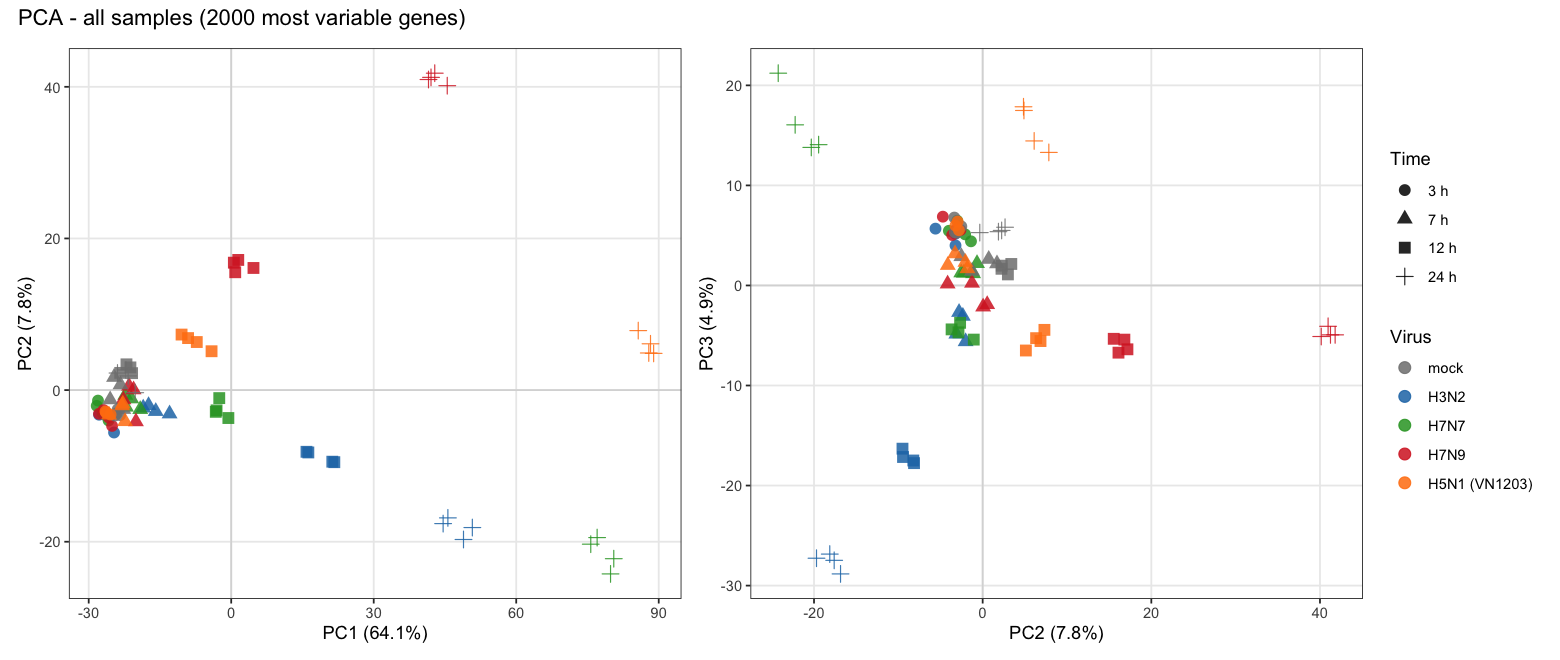

In [3]:
top  <- names(sort(apply(logx, 1, var), decreasing = TRUE))[1:2000]
pca  <- prcomp(t(logx[top, ]), center = TRUE, scale. = TRUE)
pvar <- 100 * pca$sdev^2 / sum(pca$sdev^2)
sc   <- cbind(as.data.frame(pca$x[, 1:3]), meta[rownames(pca$x), ])

plot_pca <- function(x, y) {
  ggplot(sc, aes(.data[[x]], .data[[y]], colour = virus, shape = hour_f)) +
    geom_hline(yintercept = 0, colour = "grey85") +
    geom_vline(xintercept = 0, colour = "grey85") +
    geom_point(size = 3, alpha = .85) +
    scale_colour_manual(values = virus_cols) +
    labs(x = sprintf("%s (%.1f%%)", x, pvar[as.integer(sub("PC", "", x))]),
         y = sprintf("%s (%.1f%%)", y, pvar[as.integer(sub("PC", "", y))]),
         colour = "Virus", shape = "Time")
}

p_pca <- plot_pca("PC1", "PC2") + plot_pca("PC2", "PC3") +
  plot_layout(guides = "collect") + plot_annotation(title = "PCA - all samples (2000 most variable genes)")
options(repr.plot.width = 13, repr.plot.height = 5.5)
print(p_pca)
save_plot(p_pca, "Fig1_PCA", width = 13, height = 5.5)

**Interpretation**
- **PC1 (64 %)** = strength of the infection response: mock and early samples (3–7 h) on the left, 24 h samples far on the right.
  → infection has a massive effect on the transcriptome: there is something to analyse.
- At **3–7 h** all viruses cluster with mock; the viruses **diverge from 12 h** onwards.
- **PC2** isolates **H7N9** (12 h and 24 h samples move up alone); **PC3** separates **H3N2** from H7N7 / H5N1.
  → H7N9 follows its own trajectory.

## 3. Differential expression — when does the response start?

limma-trend on log2 data (data are already normalised), one group per virus × time, each virus compared with mock
at the same time point. DEG = FDR < 0.05 and |log2FC| > 1.

In [4]:
expr <- logx[rowMeans(logx) > 1, rownames(meta)]               # remove lowly expressed genes
meta$group <- factor(paste(meta$virus_id, meta$hour, sep = "_"))
design <- model.matrix(~ 0 + group, data = meta)
colnames(design) <- levels(meta$group)
fit <- lmFit(expr, design)

# run a set of contrasts and return one table per contrast (with DEG status)
run_contrasts <- function(defs, names) {
  cm <- makeContrasts(contrasts = defs, levels = design)
  colnames(cm) <- names
  f <- eBayes(contrasts.fit(fit, cm), trend = TRUE)
  lapply(setNames(names, names), function(n) {
    tt <- topTable(f, coef = n, number = Inf, sort.by = "P")
    tt$gene   <- rownames(tt)
    tt$status <- ifelse(tt$adj.P.Val < padj_thr & tt$logFC >  lfc_thr, "Up",
                 ifelse(tt$adj.P.Val < padj_thr & tt$logFC < -lfc_thr, "Down", "NS"))
    tt
  })
}

grid        <- expand.grid(virus = viruses, hour = hours, stringsAsFactors = FALSE)
contr_names <- paste0(grid$virus, "_", grid$hour, "h_vs_mock")
de_list     <- run_contrasts(paste0(grid$virus, "_", grid$hour, " - mock_", grid$hour), contr_names)

,virus,hour,Up,Down
,<fct>,<fct>,<int>,<int>
H3N2_3h_vs_mock,H3N2,3 h,247,164
H7N7_3h_vs_mock,H7N7,3 h,234,112
H7N9_3h_vs_mock,H7N9,3 h,169,131
VN1203_3h_vs_mock,H5N1 (VN1203),3 h,232,135
H3N2_7h_vs_mock,H3N2,7 h,243,86
H7N7_7h_vs_mock,H7N7,7 h,145,76
H7N9_7h_vs_mock,H7N9,7 h,144,81
VN1203_7h_vs_mock,H5N1 (VN1203),7 h,26,9
H3N2_12h_vs_mock,H3N2,12 h,1505,1273


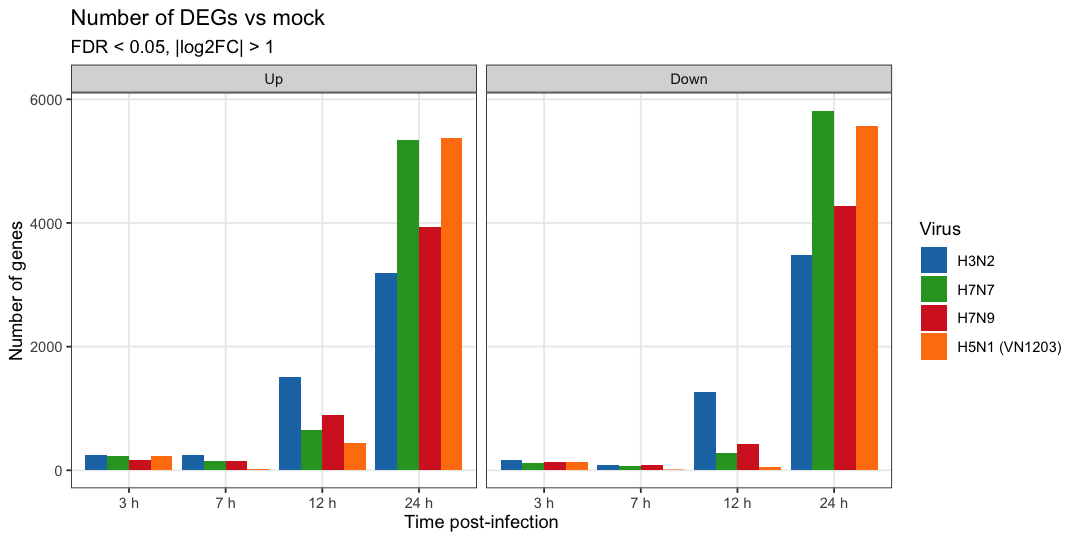

In [5]:
deg <- data.frame(virus = factor(sub("VN1203", "H5N1 (VN1203)", grid$virus), levels = names(virus_cols)[-1]),
                  hour  = factor(paste0(grid$hour, " h"), levels = paste0(hours, " h")),
                  Up    = sapply(de_list, function(t) sum(t$status == "Up")),
                  Down  = sapply(de_list, function(t) sum(t$status == "Down")))
write.csv(deg, file.path(out_dir, "DEG_counts.csv"), row.names = FALSE)
deg

deg_long <- rbind(data.frame(deg[, 1:2], direction = "Up",   n = deg$Up),
                  data.frame(deg[, 1:2], direction = "Down", n = deg$Down))
p_deg <- ggplot(deg_long, aes(hour, n, fill = virus)) +
  geom_col(position = "dodge") +
  facet_wrap(~ factor(direction, levels = c("Up", "Down"))) +
  scale_fill_manual(values = virus_cols) +
  labs(title = "Number of DEGs vs mock",
       subtitle = sprintf("FDR < %.2f, |log2FC| > %g", padj_thr, lfc_thr),
       x = "Time post-infection", y = "Number of genes", fill = "Virus")
options(repr.plot.width = 9, repr.plot.height = 4.5)
print(p_deg)
save_plot(p_deg, "Fig2_DEG_counts", width = 9, height = 4.5)

**Interpretation:** at 3 h and 7 h only a few hundred genes change; the response really starts at **12 h**
and explodes at **24 h** (several thousand DEGs for every virus). The differences between viruses also appear from 12 h.

## 4. Enrichment (enrichR) + heatmap — which processes are hit?

Over-representation analysis (ORA) with **enrichR** on the Up and Down DEGs of each contrast, using the
**MSigDB Hallmark** collection (50 well-defined biological processes). Shown: Hallmarks significant (adj. p < 0.05)
in at least 2 contrasts. Results are cached in `Results/Story/enrichR_Hallmark.csv` (delete it to re-query enrichR).

In [6]:
invisible(capture.output(setEnrichrSite("Enrichr"), type = "message"))
ora_db   <- "MSigDB_Hallmark_2020"
ora_file <- file.path(out_dir, "enrichR_Hallmark.csv")

if (file.exists(ora_file)) {
  ora <- read.csv(ora_file)
} else {
  ora <- NULL
  for (cn in contr_names) for (dir_name in c("Up", "Down")) {
    genes <- de_list[[cn]]$gene[de_list[[cn]]$status == dir_name]
    if (length(genes) < 10) next
    r <- suppressMessages(enrichr(genes, ora_db))[[ora_db]]
    Sys.sleep(0.5)                                     # be polite to the server
    if (nrow(r) > 0) ora <- rbind(ora, data.frame(contrast = cn, direction = dir_name, r[, c("Term", "Overlap", "Adjusted.P.value", "Genes")]))
  }
  write.csv(ora, ora_file, row.names = FALSE)
}
ora$virus <- sub("_.*", "", ora$contrast)
ora$hour  <- as.integer(sub("h", "", sapply(strsplit(ora$contrast, "_"), `[`, 2)))

Connection changed to https://maayanlab.cloud/Enrichr/



Connection is Live!




    Interferon Alpha Response     Interferon Gamma Response 
                           11                            11 
     IL-6/JAK/STAT3 Signaling         Inflammatory Response 
                            9                             9 
TNF-alpha Signaling via NF-kB           Allograft Rejection 
                            8                             5 

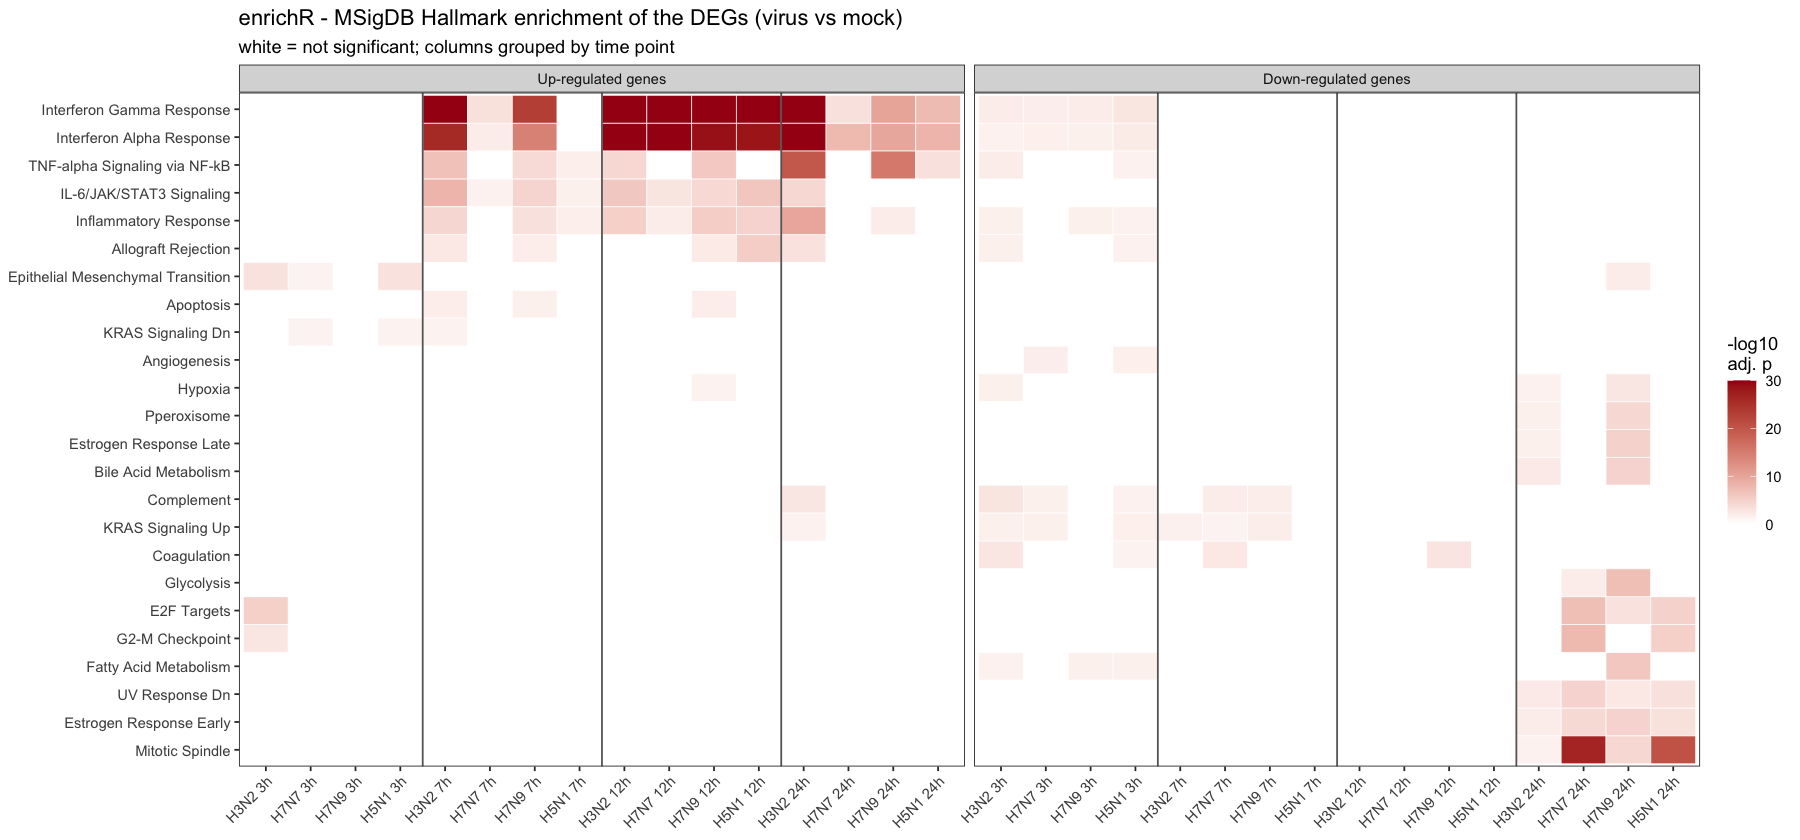

In [7]:
sig   <- ora[ora$Adjusted.P.value < 0.05, ]
keep  <- names(which(table(sig$Term) >= 2))                        # Hallmarks significant in >= 2 contrasts
heat  <- expand.grid(Term = keep, contrast = contr_names, direction = c("Up", "Down"), stringsAsFactors = FALSE)
heat  <- merge(heat, ora[, c("Term", "contrast", "direction", "Adjusted.P.value")], all.x = TRUE)
heat$score <- pmin(-log10(ifelse(is.na(heat$Adjusted.P.value), 1, heat$Adjusted.P.value)), 30)
heat$score[heat$score < -log10(0.05)] <- 0                          # non-significant -> blank
v <- sub("_.*", "", heat$contrast); h <- sub("h", "", sapply(strsplit(heat$contrast, "_"), `[`, 2))
heat$label <- factor(paste0(sub("VN1203", "H5N1", v), " ", h, "h"),
                     levels = paste0(rep(sub("VN1203", "H5N1", viruses), 4), " ", rep(hours, each = 4), "h"))
up_score  <- tapply(heat$score[heat$direction == "Up"],   heat$Term[heat$direction == "Up"],   sum)
dn_score  <- tapply(heat$score[heat$direction == "Down"], heat$Term[heat$direction == "Down"], sum)
heat$Term <- factor(heat$Term, levels = names(sort(up_score - dn_score[names(up_score)])))
heat$direction <- factor(heat$direction, levels = c("Up", "Down"),
                         labels = c("Up-regulated genes", "Down-regulated genes"))

p_heat <- ggplot(heat, aes(label, Term, fill = score)) +
  geom_tile(colour = "white") +
  geom_vline(xintercept = c(4.5, 8.5, 12.5), colour = "grey40") +
  facet_wrap(~ direction) +
  scale_fill_gradient(low = "white", high = "#a50f15", name = "-log10\nadj. p") +
  labs(title = "enrichR - MSigDB Hallmark enrichment of the DEGs (virus vs mock)",
       subtitle = "white = not significant; columns grouped by time point", x = NULL, y = NULL) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1), panel.grid = element_blank())
options(repr.plot.width = 15, repr.plot.height = 7)
print(p_heat)
save_plot(p_heat, "Fig3_enrichR_heatmap", width = 15, height = 7)

# how often each Hallmark is enriched among the Up genes
head(sort(table(sig$Term[sig$direction == "Up"]), decreasing = TRUE), 6)

**Interpretation:** the up-regulated genes are dominated by the **interferon α and γ responses**
(the most frequently enriched Hallmarks), followed by inflammation (TNF-α/NF-κB, IL-6/JAK/STAT3, inflammatory response).
→ Interferon is the main antiviral defence against influenza and the strongest signal in the data:
**we focus on the interferon response** and compare its dynamics between viruses.

## 5. Interferon dynamics

**A** — expression of **IFNB1** (IFN-β, the first interferon produced by infected cells) over time.
The box gives the direct limma comparison **H7N9 vs each virus at 24 h**.
**B** — % of the genes of the interferon α / γ Hallmarks that are up-regulated vs mock (point size = mean log2FC of these genes).

In [8]:
# Hallmark gene sets (downloaded once from Enrichr into data/genesets/)
gs_file <- file.path("data", "genesets", "MSigDB_Hallmark_2020.gmt")
if (!file.exists(gs_file)) {
  dir.create(dirname(gs_file), recursive = TRUE, showWarnings = FALSE)
  download.file("https://maayanlab.cloud/Enrichr/geneSetLibrary?mode=text&libraryName=MSigDB_Hallmark_2020", gs_file, quiet = TRUE)
}
hall <- lapply(strsplit(readLines(gs_file, warn = FALSE), "\t"), function(x) {
  g <- sub(",.*", "", x[-(1:2)]); unique(g[g != ""]) })
names(hall) <- sapply(strsplit(readLines(gs_file, warn = FALSE), "\t"), `[`, 1)

# direct comparison H7N9 vs each other virus at 24 h
others  <- c("H3N2", "H7N7", "VN1203")
h7_24 <- run_contrasts(paste0("H7N9_24 - ", others, "_24"), paste0("H7N9_vs_", others, "_24h"))

# --- figure helpers --------------------------------------------------
# A: expression of a few genes over time (one small panel per gene, H7N9 in bold)
plot_gene_panel <- function(genes, title, ncol = 3) {
  d <- do.call(rbind, lapply(genes, function(g)
    data.frame(gene = g, meta[, c("virus", "hour")], expr = logx[g, rownames(meta)])))
  m <- aggregate(expr ~ gene + virus + hour, d, function(x) c(mean = mean(x), se = sd(x) / sqrt(length(x))))
  m <- data.frame(m[, c("gene", "virus", "hour")], mean = m$expr[, "mean"], se = m$expr[, "se"])
  m$gene <- factor(m$gene, levels = genes)
  ggplot(m, aes(hour, mean, colour = virus, group = virus)) +
    geom_errorbar(aes(ymin = mean - se, ymax = mean + se), width = .6, linewidth = .4) +
    geom_line(aes(linewidth = virus == "H7N9")) +
    geom_point(size = 1.8) +
    facet_wrap(~ gene, scales = "free_y", ncol = ncol) +
    scale_linewidth_manual(values = c(`TRUE` = 1.8, `FALSE` = .7), guide = "none") +
    scale_colour_manual(values = virus_cols) +
    scale_x_continuous(breaks = hours, labels = paste0(hours, "h")) +
    labs(title = title, subtitle = "Mean +/- SEM of replicates; H7N9 in bold",
         x = "Time post-infection", y = "Expression (log2 normalised counts + 1)", colour = "Virus") +
    theme(strip.text = element_text(face = "bold.italic"))
}

# B: % of the genes of each Hallmark that are up- (or down-) regulated vs mock
plot_pathway_pct <- function(pathways, direction = "Up", title) {
  d <- do.call(rbind, lapply(contr_names, function(cn) do.call(rbind, lapply(pathways, function(pw) {
    x  <- de_list[[cn]][de_list[[cn]]$gene %in% hall[[pw]], ]
    ok <- x$status == direction
    data.frame(contrast = cn, pathway = paste0(pw, " (", nrow(x), " genes)"),
               pct = 100 * mean(ok), lfc = if (any(ok)) mean(abs(x$logFC[ok])) else 0)
  }))))
  d$virus   <- factor(sub("VN1203", "H5N1 (VN1203)", sub("_.*", "", d$contrast)), levels = names(virus_cols)[-1])
  d$hour    <- as.integer(sub("h", "", sapply(strsplit(d$contrast, "_"), `[`, 2)))
  d$pathway <- factor(d$pathway, levels = unique(d$pathway))
  d <- d[order(d$hour), ]
  word <- if (direction == "Up") "up-regulated" else "down-regulated"
  ggplot(d, aes(hour, pct, colour = virus, group = virus)) +
    geom_line(aes(linewidth = virus == "H7N9")) +
    geom_point(aes(size = lfc)) +
    facet_wrap(~ pathway, ncol = 1) +
    scale_linewidth_manual(values = c(`TRUE` = 2, `FALSE` = .8), guide = "none") +
    scale_size_continuous(range = c(1.5, 7), name = paste0("Mean |log2FC| of\n", word, " genes")) +
    scale_colour_manual(values = virus_cols) +
    scale_x_continuous(breaks = hours, labels = paste0(hours, " h")) +
    labs(title = title, subtitle = sprintf("%% of pathway genes %s vs mock (FDR < 0.05, |log2FC| > 1)", word),
         x = "Time post-infection", y = paste("% of pathway genes", word), colour = "Virus") +
    theme(strip.text = element_text(face = "bold", hjust = 0))
}

# A + B side by side
combine_ab <- function(pa, pb, name, width = 16, height = 7) {
  p <- (pa + labs(tag = "A")) + (pb + labs(tag = "B") + guides(colour = "none")) + plot_layout(widths = c(1.15, 1))
  options(repr.plot.width = width, repr.plot.height = height)
  print(p)
  save_plot(p, name, width = width, height = height)
  invisible(p)
}

vs,fold_lower,FDR
<chr>,<dbl>,<dbl>
H3N2,74,7.4e-32
H7N7,21,2.6e-24
H5N1,17,9.9e-23


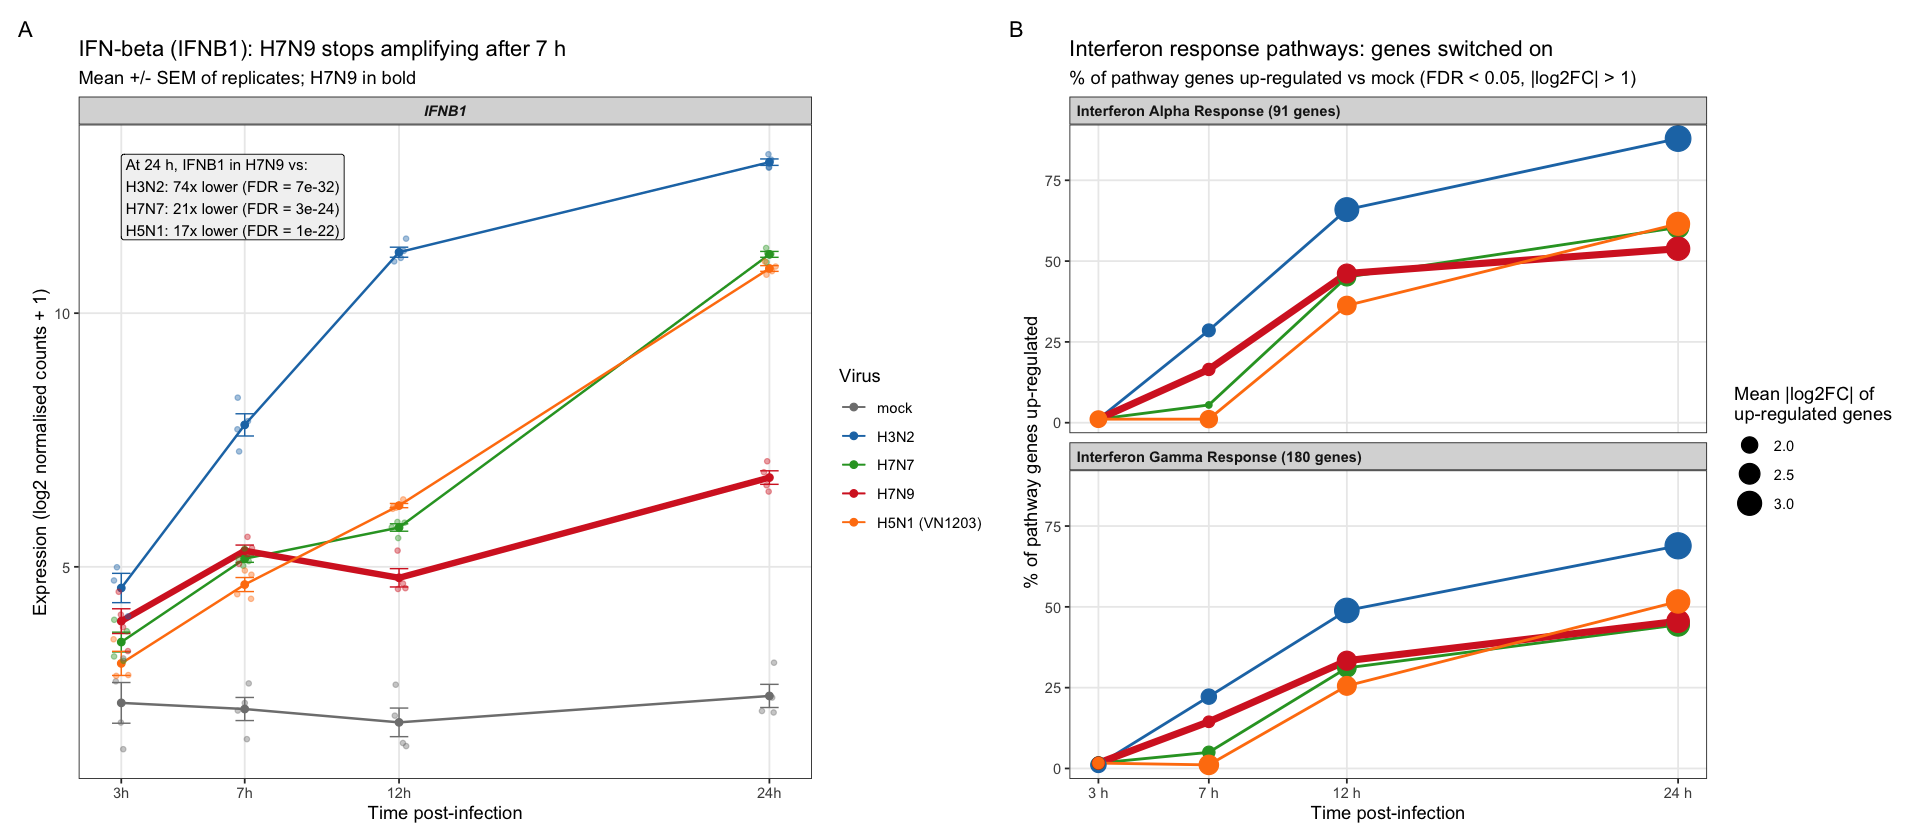

In [9]:
# A: IFNB1, with the H7N9 vs others statistics at 24 h
st <- do.call(rbind, lapply(others, function(o) {
  t <- h7_24[[paste0("H7N9_vs_", o, "_24h")]]["IFNB1", ]
  data.frame(vs = sub("VN1203", "H5N1", o), fold_lower = round(2^-t$logFC), FDR = signif(t$adj.P.Val, 2))
}))
st
box <- paste0("At 24 h, IFNB1 in H7N9 vs:\n",
              paste(sprintf("%s: %dx lower (FDR = %.0e)", st$vs, st$fold_lower, st$FDR), collapse = "\n"))

d_ifnb <- data.frame(meta[, c("virus", "hour")], expr = logx["IFNB1", rownames(meta)])
p_ifnb <- plot_gene_panel("IFNB1", "IFN-beta (IFNB1): H7N9 stops amplifying after 7 h") +
  geom_jitter(data = d_ifnb, aes(hour, expr), width = .25, height = 0, size = 1.2, alpha = .4) +
  annotate("label", x = 3, y = max(d_ifnb$expr), label = box, hjust = 0, vjust = 1, size = 3.2, fill = "grey95")

p_ifn_path <- plot_pathway_pct(c("Interferon Alpha Response", "Interferon Gamma Response"), "Up",
                               "Interferon response pathways: genes switched on")
p_fig_ifn <- combine_ab(p_ifnb, p_ifn_path, "Fig4_interferon")

**Interpretation**
- **A:** all viruses induce IFN-β early. H7N9 follows the other avian viruses until 7 h, then **stops amplifying**
  (plateau / slight decrease at 12 h) while all the other viruses keep increasing. At 24 h IFNB1 is **17–74× lower**
  in H7N9 than in each of the other viruses.
- **B:** the downstream interferon response is switched on by all viruses, but at 24 h H7N9 activates the smallest
  fraction of interferon genes (e.g. 54 % of the IFN-α Hallmark vs 61–88 % for the other viruses).
- → H7N9 starts an interferon response but **fails to amplify it after 12 h**.

## 6. Cytokines / chemokines — consequence for inflammation

If interferon is limited from 12 h, the chemokines that depend on it should be reduced in H7N9.
**A** — key inflammatory cytokines (IL6, TNF) and **interferon-induced chemokines** (CXCL9, CXCL10, CXCL11, CCL5).
**B** — % of genes switched on in the inflammation Hallmarks.

,H7N9_vs_H3N2_24h,H7N9_vs_H7N7_24h,H7N9_vs_VN1203_24h
IL6,-4.31,-1.53,-3.39
TNF,-1.64,1.92,-1.95
CCL5,-4.78,-2.93,-2.68
CXCL9,-5.44,-4.40,-4.47
CXCL10,-4.47,-0.99,-1.97
CXCL11,-4.76,-1.91,-2.12


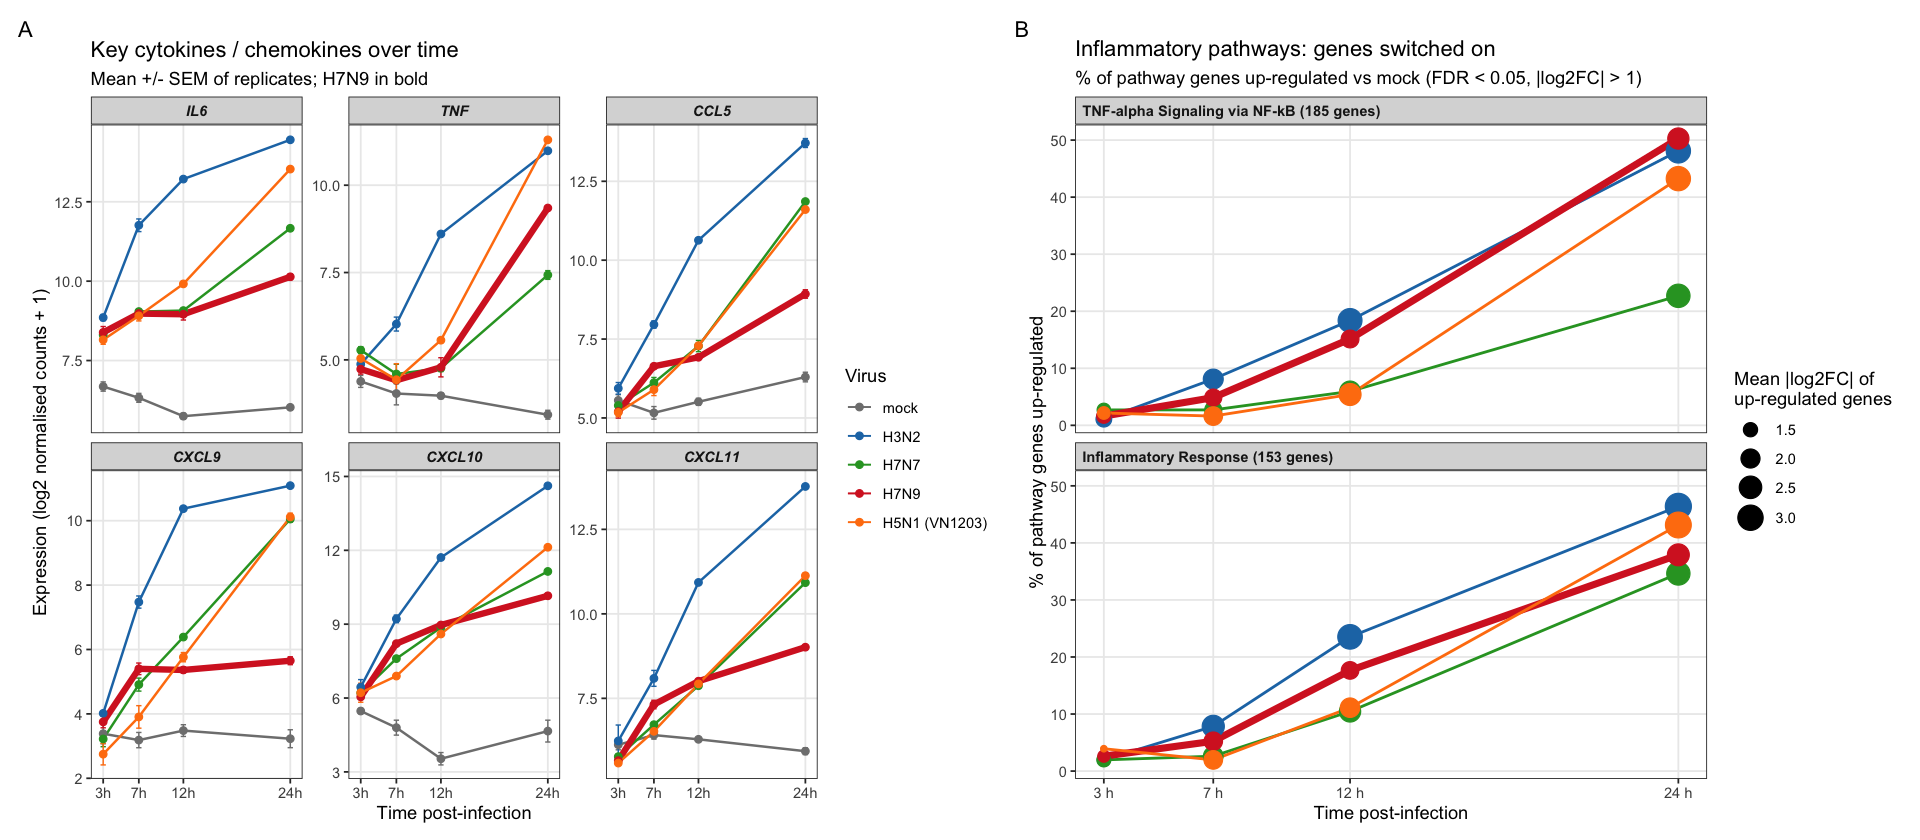

In [10]:
cyto_genes <- c("IL6", "TNF", "CCL5", "CXCL9", "CXCL10", "CXCL11")
p_cyto_a <- plot_gene_panel(cyto_genes, "Key cytokines / chemokines over time")
p_cyto_b <- plot_pathway_pct(c("TNF-alpha Signaling via NF-kB", "Inflammatory Response"), "Up",
                             "Inflammatory pathways: genes switched on")
p_fig_cyto <- combine_ab(p_cyto_a, p_cyto_b, "Fig5_cytokines")

# H7N9 vs each virus at 24 h for these genes (log2FC < 0 = lower in H7N9)
sapply(h7_24, function(t) setNames(round(t[cyto_genes, "logFC"], 2), cyto_genes))

**Interpretation**
- The **interferon-induced chemokines CXCL9, CXCL10, CXCL11 and CCL5** follow the same profile as IFN-β: H7N9 plateaus
  after 7 h and is the lowest of the 4 viruses at 24 h. **IL6** is also lowest in H7N9.
- **TNF** and the NF-κB pathway as a whole (panel B) are **not** reduced in H7N9: the defect is not a global loss of
  inflammation but a loss of the **interferon-dependent chemokines**, which recruit T cells and NK cells.

## 7. Conclusion

H7N9 triggers the same early antiviral programme as the other influenza viruses, but **fails to amplify the type I
interferon response after 7–12 h**. As a consequence, the interferon-induced chemokines that recruit immune cells are
reduced at 24 h. This attenuated alarm signal could favour viral replication and delay immune recruitment
(hypothesis — transcriptomic data only, one cell model).